# Machine Learning CA1: NHANES Depression Risk

## Step 1: Import necessary libraries and Load Dataset

In [1]:
# Import libraries used across the notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
# Load each NHANES dataset using its CSV filename.
df_DEMO = pd.read_csv("DEMO_L.csv")# Demographic data, including age, sex, and race/ethnicity
df_DPQ = pd.read_csv("DPQ_L.csv")  # Depression screener questionnaire (PHQ-9)
df_MCQ = pd.read_csv("MCQ_L.csv")  # Medical conditions and health history data
df_INQ = pd.read_csv("INQ_L.csv")  # Household income and income-to-poverty ratio data
df_PAQ = pd.read_csv("PAQ_L.csv")  # Physical activity and exercise data
df_SLQ = pd.read_csv("SLQ_L.csv")  # Sleep and sleep habits data
df_ALQ = pd.read_csv("ALQ_L.csv")  # Alcohol use data
df_BMX = pd.read_csv("BMX_L.csv")  # Body measurements, including weight, height, and BMI

## Step 2: Data Exploration

Explore each NHANES file separately, following the dataset order used in the Proposal Notebook. These checks do not modify the data.

### 2.1 Demographic (DEMO_L) dataset overall

In [3]:
# Check the dataset row and column count.
print("Demographic shape:", df_DEMO.shape)

Demographic shape: (11933, 27)


In [4]:
# Check column data types and non-missing counts.
df_DEMO.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   SDDSRVYR  11933 non-null  float64
 2   RIDSTATR  11933 non-null  float64
 3   RIAGENDR  11933 non-null  float64
 4   RIDAGEYR  11933 non-null  float64
 5   RIDAGEMN  377 non-null    float64
 6   RIDRETH1  11933 non-null  float64
 7   RIDRETH3  11933 non-null  float64
 8   RIDEXMON  8860 non-null   float64
 9   RIDEXAGM  2787 non-null   float64
 10  DMQMILIZ  8301 non-null   float64
 11  DMDBORN4  11914 non-null  float64
 12  DMDYRUSR  1875 non-null   float64
 13  DMDEDUC2  7794 non-null   float64
 14  DMDMARTZ  7792 non-null   float64
 15  RIDEXPRG  1503 non-null   float64
 16  DMDHHSIZ  11933 non-null  float64
 17  DMDHRGND  4115 non-null   float64
 18  DMDHRAGZ  4124 non-null   float64
 19  DMDHREDZ  3746 non-null   float64
 20  DMDHRMAZ  4020 non-null   float64
 21  

In [5]:
# Count missing values by column.
print("\nMissing values in Demographic:")
print(df_DEMO.isnull().sum())


Missing values in Demographic:
SEQN            0
SDDSRVYR        0
RIDSTATR        0
RIAGENDR        0
RIDAGEYR        0
RIDAGEMN    11556
RIDRETH1        0
RIDRETH3        0
RIDEXMON     3073
RIDEXAGM     9146
DMQMILIZ     3632
DMDBORN4       19
DMDYRUSR    10058
DMDEDUC2     4139
DMDMARTZ     4141
RIDEXPRG    10430
DMDHHSIZ        0
DMDHRGND     7818
DMDHRAGZ     7809
DMDHREDZ     8187
DMDHRMAZ     7913
DMDHSEDZ     9806
WTINT2YR        0
WTMEC2YR        0
SDMVSTRA        0
SDMVPSU         0
INDFMPIR     2041
dtype: int64


In [6]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Demographic:")
print(df_DEMO.describe())

Descriptive statistics for Demographic:
                SEQN  SDDSRVYR      RIDSTATR      RIAGENDR      RIDAGEYR  \
count   11933.000000   11933.0  11933.000000  11933.000000  1.193300e+04   
mean   136344.000000      12.0      1.742479      1.532808  3.831786e+01   
std      3444.904716       0.0      0.437287      0.498943  2.560199e+01   
min    130378.000000      12.0      1.000000      1.000000  5.397605e-79   
25%    133361.000000      12.0      1.000000      1.000000  1.300000e+01   
50%    136344.000000      12.0      2.000000      2.000000  3.700000e+01   
75%    139327.000000      12.0      2.000000      2.000000  6.200000e+01   
max    142310.000000      12.0      2.000000      2.000000  8.000000e+01   

           RIDAGEMN      RIDRETH1      RIDRETH3     RIDEXMON      RIDEXAGM  \
count  3.770000e+02  11933.000000  11933.000000  8860.000000  2.787000e+03   
mean   1.162865e+01      3.104584      3.320540     1.520203  1.219085e+02   
std    6.805429e+00      1.076346      1.

In [7]:
# Summarize the age distribution.
print("Age distribution:")
print(df_DEMO["RIDAGEYR"].describe())

Age distribution:
count    1.193300e+04
mean     3.831786e+01
std      2.560199e+01
min      5.397605e-79
25%      1.300000e+01
50%      3.700000e+01
75%      6.200000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64


### 2.2 Depression Screener (DPQ_L) dataset overall

In [8]:
# Check the dataset row and column count.
print("Depression Screener shape:", df_DPQ.shape)

Depression Screener shape: (6337, 11)


In [9]:
# Check column data types and non-missing counts.
df_DPQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 6337 entries, 0 to 6336
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6337 non-null   float64
 1   DPQ010  5519 non-null   float64
 2   DPQ020  5518 non-null   float64
 3   DPQ030  5516 non-null   float64
 4   DPQ040  5514 non-null   float64
 5   DPQ050  5513 non-null   float64
 6   DPQ060  5510 non-null   float64
 7   DPQ070  5508 non-null   float64
 8   DPQ080  5508 non-null   float64
 9   DPQ090  5506 non-null   float64
 10  DPQ100  4167 non-null   float64
dtypes: float64(11)
memory usage: 544.7 KB


In [10]:
# Count missing values by column.
print("\nMissing values in Depression Screener:")
print(df_DPQ.isnull().sum())


Missing values in Depression Screener:
SEQN         0
DPQ010     818
DPQ020     819
DPQ030     821
DPQ040     823
DPQ050     824
DPQ060     827
DPQ070     829
DPQ080     829
DPQ090     831
DPQ100    2170
dtype: int64


In [11]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Depression Screener:")
print(df_DPQ.describe())

Descriptive statistics for Depression Screener:
                SEQN        DPQ010        DPQ020        DPQ030        DPQ040  \
count    6337.000000  5.519000e+03  5.518000e+03  5.516000e+03  5.514000e+03   
mean   136348.738362  5.109621e-01  4.786154e-01  7.935098e-01  8.601741e-01   
std      3439.132476  9.466645e-01  8.387239e-01  1.003693e+00  9.651269e-01   
min    130378.000000  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
25%    133337.000000  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
50%    136397.000000  5.397605e-79  5.397605e-79  5.397605e-79  1.000000e+00   
75%    139310.000000  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
max    142310.000000  9.000000e+00  9.000000e+00  9.000000e+00  9.000000e+00   

             DPQ050        DPQ060        DPQ070        DPQ080        DPQ090  \
count  5.513000e+03  5.510000e+03  5.508000e+03  5.508000e+03  5.506000e+03   
mean   5.042627e-01  4.110708e-01  3.948802e-01  2.165940e-01  8.209226e-

In [12]:
# Review distributions for the nine PHQ-9 items.
print("Distribution of PHQ-9 item responses:")
print(df_DPQ[["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050", "DPQ060", "DPQ070", "DPQ080", "DPQ090"]].describe())

Distribution of PHQ-9 item responses:
             DPQ010        DPQ020        DPQ030        DPQ040        DPQ050  \
count  5.519000e+03  5.518000e+03  5.516000e+03  5.514000e+03  5.513000e+03   
mean   5.109621e-01  4.786154e-01  7.935098e-01  8.601741e-01  5.042627e-01   
std    9.466645e-01  8.387239e-01  1.003693e+00  9.651269e-01  8.605773e-01   
min    5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
25%    5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
50%    5.397605e-79  5.397605e-79  5.397605e-79  1.000000e+00  5.397605e-79   
75%    1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
max    9.000000e+00  9.000000e+00  9.000000e+00  9.000000e+00  9.000000e+00   

             DPQ060        DPQ070        DPQ080        DPQ090  
count  5.510000e+03  5.508000e+03  5.508000e+03  5.506000e+03  
mean   4.110708e-01  3.948802e-01  2.165940e-01  8.209226e-02  
std    7.869793e-01  7.675240e-01  6.850770e-01  4.381644e

#### PHQ-9 Item Response Counts


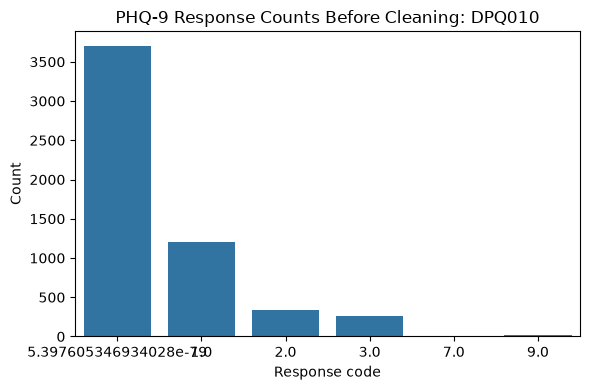

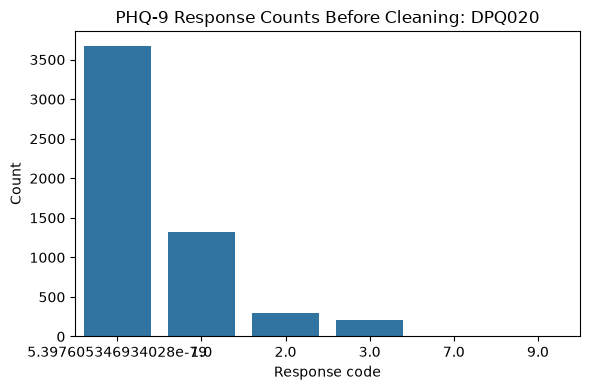

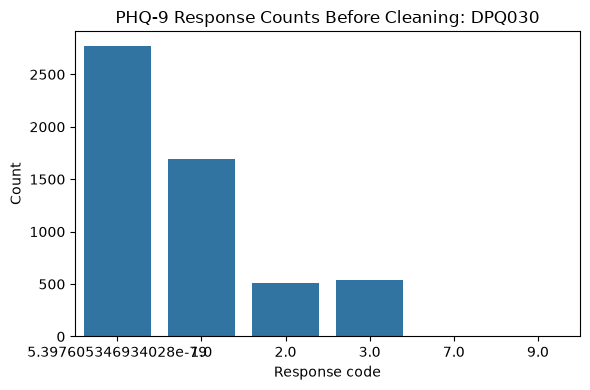

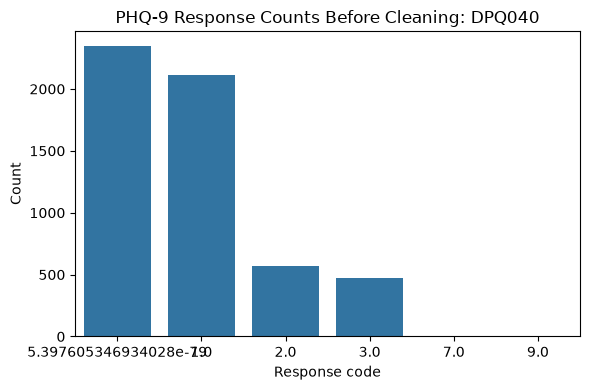

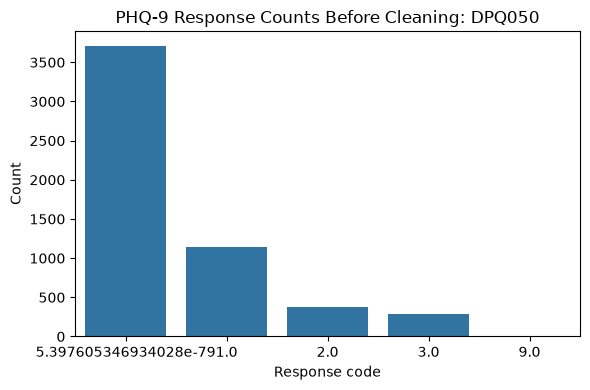

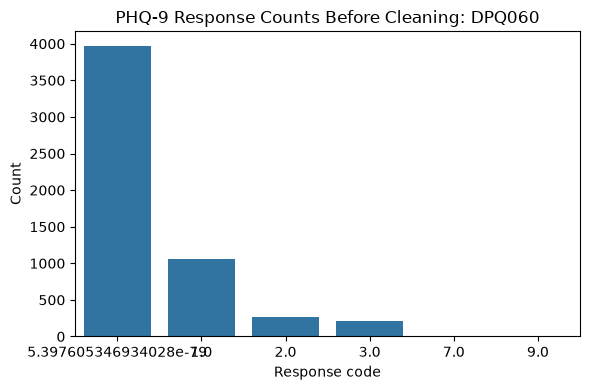

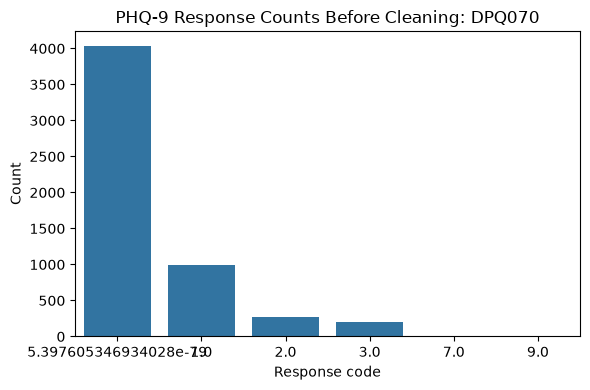

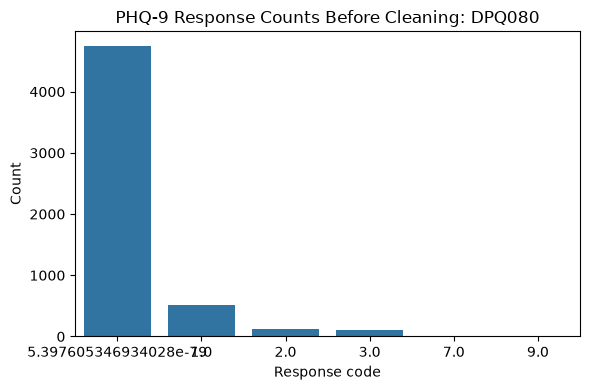

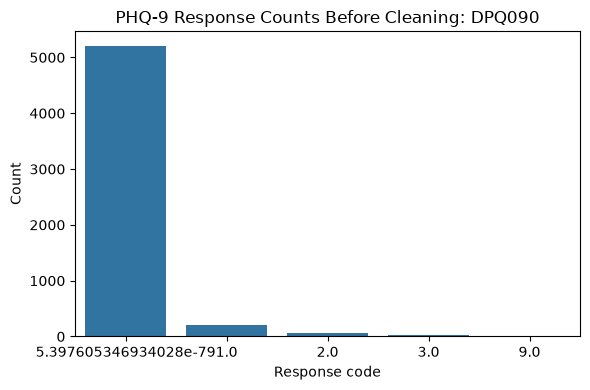

In [13]:
# Plot raw response-code counts for each PHQ-9 item before cleaning.
dpq_plot_items = ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050",
                  "DPQ060", "DPQ070", "DPQ080", "DPQ090"]
for col in dpq_plot_items:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col, data=df_DPQ)
    plt.title("PHQ-9 Response Counts Before Cleaning: " + col)
    plt.xlabel("Response code")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

### 2.3 Medical Conditions (MCQ_L) dataset overall

In [14]:
# Check the dataset row and column count.
print("Medical Conditions shape:", df_MCQ.shape)

Medical Conditions shape: (11744, 35)


In [15]:
# Check column data types and non-missing counts.
df_MCQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 11744 entries, 0 to 11743
Data columns (total 35 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     11744 non-null  float64
 1   MCQ010   11743 non-null  float64
 2   MCQ035   1946 non-null   float64
 3   MCQ040   1219 non-null   float64
 4   MCQ050   1219 non-null   float64
 5   AGQ030   11743 non-null  float64
 6   MCQ053   11741 non-null  float64
 7   MCQ149   434 non-null    float64
 8   MCQ160A  7807 non-null   float64
 9   MCQ195   2532 non-null   float64
 10  MCQ160B  7808 non-null   float64
 11  MCQ160C  7807 non-null   float64
 12  MCQ160D  7808 non-null   float64
 13  MCQ160E  7807 non-null   float64
 14  MCQ160F  7806 non-null   float64
 15  MCQ160M  7806 non-null   float64
 16  MCQ170M  1053 non-null   float64
 17  MCQ160P  7807 non-null   float64
 18  MCQ160L  7807 non-null   float64
 19  MCQ170L  425 non-null    float64
 20  MCQ500   1578 non-null   float64
 21  MCQ510A  260 non-null  

In [16]:
# Count missing values by column.
print("\nMissing values in Medical Conditions:")
print(df_MCQ.isnull().sum())


Missing values in Medical Conditions:
SEQN           0
MCQ010         1
MCQ035      9798
MCQ040     10525
MCQ050     10525
AGQ030         1
MCQ053         3
MCQ149     11310
MCQ160A     3937
MCQ195      9212
MCQ160B     3936
MCQ160C     3937
MCQ160D     3936
MCQ160E     3937
MCQ160F     3938
MCQ160M     3938
MCQ170M    10691
MCQ160P     3937
MCQ160L     3937
MCQ170L    11319
MCQ500     10166
MCQ510A    11484
MCQ510B    11740
MCQ510C    11697
MCQ510D    11682
MCQ510E    11728
MCQ510F    11665
MCQ550      3937
MCQ560      3937
MCQ220      3937
MCQ230A    10575
MCQ230B    11585
MCQ230C    11718
MCQ230D    11742
OSQ230      6021
dtype: int64


In [17]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Medical Conditions:")
print(df_MCQ.describe())

Descriptive statistics for Medical Conditions:
                SEQN        MCQ010      MCQ035       MCQ040       MCQ050  \
count   11744.000000  11743.000000  1946.00000  1219.000000  1219.000000   
mean   136347.896373      1.843226     1.50668     1.538146     1.879409   
std      3445.908868      0.451382     1.14690     0.657767     0.445073   
min    130378.000000      1.000000     1.00000     1.000000     1.000000   
25%    133359.750000      2.000000     1.00000     1.000000     2.000000   
50%    136354.500000      2.000000     1.00000     2.000000     2.000000   
75%    139327.250000      2.000000     2.00000     2.000000     2.000000   
max    142310.000000      9.000000     9.00000     9.000000     9.000000   

             AGQ030        MCQ053      MCQ149      MCQ160A       MCQ195  ...  \
count  11743.000000  11741.000000  434.000000  7807.000000  2532.000000  ...   
mean       1.830537      1.967720    1.884793     1.690918     3.093602  ...   
std        0.439566      0.2

### 2.4 Income (INQ_L) dataset overall

In [18]:
# Check the dataset row and column count.
print("Income shape:", df_INQ.shape)

Income shape: (11933, 5)


In [19]:
# Check column data types and non-missing counts.
df_INQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   INDFMMPI  8989 non-null   float64
 2   INDFMMPC  10464 non-null  float64
 3   INQ300    10468 non-null  float64
 4   IND310    5650 non-null   float64
dtypes: float64(5)
memory usage: 466.3 KB


In [20]:
# Count missing values by column.
print("\nMissing values in Income:")
print(df_INQ.isnull().sum())


Missing values in Income:
SEQN           0
INDFMMPI    2944
INDFMMPC    1469
INQ300      1465
IND310      6283
dtype: int64


In [21]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Income:")
print(df_INQ.describe())

Descriptive statistics for Income:
                SEQN      INDFMMPI      INDFMMPC        INQ300       IND310
count   11933.000000  8.989000e+03  10464.000000  10468.000000  5650.000000
mean   136344.000000  2.529415e+00      2.419438      1.796141     3.606549
std      3444.904716  1.607884e+00      1.315262      1.299623    13.268089
min    130378.000000  5.397605e-79      1.000000      1.000000     1.000000
25%    133361.000000  1.160000e+00      1.000000      1.000000     1.000000
50%    136344.000000  2.160000e+00      3.000000      2.000000     1.000000
75%    139327.000000  4.000000e+00      3.000000      2.000000     2.000000
max    142310.000000  5.000000e+00      9.000000      9.000000    99.000000


### 2.5 Physical Activity (PAQ_L) dataset overall

In [22]:
# Check the dataset row and column count.
print("Physical Activity shape:", df_PAQ.shape)

Physical Activity shape: (8153, 8)


In [23]:
# Check column data types and non-missing counts.
df_PAQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 8153 entries, 0 to 8152
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     8153 non-null   float64
 1   PAD790Q  8135 non-null   float64
 2   PAD790U  8153 non-null   str    
 3   PAD800   6390 non-null   float64
 4   PAD810Q  8139 non-null   float64
 5   PAD810U  8153 non-null   str    
 6   PAD820   3687 non-null   float64
 7   PAD680   8138 non-null   float64
dtypes: float64(6), str(2)
memory usage: 509.7 KB


In [24]:
# Count missing values by column.
print("\nMissing values in Physical Activity:")
print(df_PAQ.isnull().sum())


Missing values in Physical Activity:
SEQN          0
PAD790Q      18
PAD790U       0
PAD800     1763
PAD810Q      14
PAD810U       0
PAD820     4466
PAD680       15
dtype: int64


In [25]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Physical Activity:")
print(df_PAQ.describe())

Descriptive statistics for Physical Activity:
                SEQN       PAD790Q       PAD800       PAD810Q       PAD820  \
count    8153.000000  8.135000e+03  6390.000000  8.139000e+03  3687.000000   
mean   136378.394579  6.014247e+01    93.437715  4.921084e+01    97.571467   
std      3440.455897  7.417083e+02   544.415142  6.852722e+02   605.421908   
min    130378.000000  5.397605e-79     1.000000  5.397605e-79     1.000000   
25%    133395.000000  1.000000e+00    30.000000  5.397605e-79    30.000000   
50%    136419.000000  2.000000e+00    60.000000  5.397605e-79    45.000000   
75%    139346.000000  4.000000e+00    60.000000  2.000000e+00    60.000000   
max    142310.000000  9.999000e+03  9999.000000  9.999000e+03  9999.000000   

             PAD680  
count  8.138000e+03  
mean   4.469827e+02  
std    9.174642e+02  
min    5.397605e-79  
25%    1.800000e+02  
50%    3.000000e+02  
75%    4.800000e+02  
max    9.999000e+03  


### 2.6 Sleep Disorders (SLQ_L) dataset overall

In [26]:
# Check the dataset row and column count.
print("Sleep Disorders shape:", df_SLQ.shape)

Sleep Disorders shape: (8501, 7)


In [27]:
# Check column data types and non-missing counts.
df_SLQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 8501 entries, 0 to 8500
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    8501 non-null   float64
 1   SLQ300  8501 non-null   str    
 2   SLQ310  8501 non-null   str    
 3   SLD012  8388 non-null   float64
 4   SLQ320  8501 non-null   str    
 5   SLQ330  8501 non-null   str    
 6   SLD013  8387 non-null   float64
dtypes: float64(3), str(4)
memory usage: 465.0 KB


In [28]:
# Count missing values by column.
print("\nMissing values in Sleep Disorders:")
print(df_SLQ.isnull().sum())


Missing values in Sleep Disorders:
SEQN        0
SLQ300      0
SLQ310      0
SLD012    113
SLQ320      0
SLQ330      0
SLD013    114
dtype: int64


In [29]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Sleep Disorders:")
print(df_SLQ.describe())

Descriptive statistics for Sleep Disorders:
                SEQN       SLD012       SLD013
count    8501.000000  8388.000000  8387.000000
mean   136369.136572     7.757332     8.353762
std      3443.283289     1.616056     1.730015
min    130378.000000     2.000000     2.000000
25%    133378.000000     7.000000     7.500000
50%    136402.000000     8.000000     8.500000
75%    139342.000000     8.500000     9.000000
max    142310.000000    14.000000    14.000000


### 2.7 Alcohol Use (ALQ_L) dataset overall

In [30]:
# Check the dataset row and column count.
print("Alcohol Use shape:", df_ALQ.shape)

Alcohol Use shape: (6337, 9)


In [31]:
# Check column data types and non-missing counts.
df_ALQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 6337 entries, 0 to 6336
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6337 non-null   float64
 1   ALQ111  5481 non-null   float64
 2   ALQ121  4922 non-null   float64
 3   ALQ130  4069 non-null   float64
 4   ALQ142  4082 non-null   float64
 5   ALQ270  2366 non-null   float64
 6   ALQ280  2362 non-null   float64
 7   ALQ151  4901 non-null   float64
 8   ALQ170  2358 non-null   float64
dtypes: float64(9)
memory usage: 445.7 KB


In [32]:
# Count missing values by column.
print("\nMissing values in Alcohol Use:")
print(df_ALQ.isnull().sum())


Missing values in Alcohol Use:
SEQN         0
ALQ111     856
ALQ121    1415
ALQ130    2268
ALQ142    2255
ALQ270    3971
ALQ280    3975
ALQ151    1436
ALQ170    3979
dtype: int64


In [33]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Alcohol Use:")
print(df_ALQ.describe())

Descriptive statistics for Alcohol Use:
                SEQN       ALQ111        ALQ121       ALQ130        ALQ142  \
count    6337.000000  5481.000000  4.922000e+03  4069.000000  4.082000e+03   
mean   136348.738362     1.109104  5.030679e+00     5.842959  4.742283e+00   
std      3439.132476     0.385114  4.314321e+00    54.996448  7.326042e+00   
min    130378.000000     1.000000  5.397605e-79     1.000000  5.397605e-79   
25%    133337.000000     1.000000  2.000000e+00     1.000000  5.397605e-79   
50%    136397.000000     1.000000  5.000000e+00     2.000000  4.000000e+00   
75%    139310.000000     1.000000  8.000000e+00     3.000000  9.000000e+00   
max    142310.000000     9.000000  9.900000e+01   999.000000  9.900000e+01   

             ALQ270        ALQ280       ALQ151        ALQ170  
count  2.366000e+03  2.362000e+03  4901.000000  2.358000e+03  
mean   4.838123e+00  3.545301e+00     1.821261  4.396098e+00  
std    7.785415e+00  7.133496e+00     0.458352  4.525245e+01  
min  

### 2.8 Body Measures (BMX_L) dataset overall

In [34]:
# Check the dataset row and column count.
print("Body Measures shape:", df_BMX.shape)

Body Measures shape: (8860, 22)


In [35]:
# Check column data types and non-missing counts.
df_BMX.info()

<class 'pandas.DataFrame'>
RangeIndex: 8860 entries, 0 to 8859
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      8860 non-null   float64
 1   BMDSTATS  8860 non-null   float64
 2   BMXWT     8754 non-null   float64
 3   BMIWT     345 non-null    float64
 4   BMXRECUM  454 non-null    float64
 5   BMIRECUM  18 non-null     float64
 6   BMXHEAD   70 non-null     float64
 7   BMIHEAD   0 non-null      float64
 8   BMXHT     8499 non-null   float64
 9   BMIHT     134 non-null    float64
 10  BMXBMI    8471 non-null   float64
 11  BMDBMIC   2492 non-null   float64
 12  BMXLEG    7335 non-null   float64
 13  BMILEG    396 non-null    float64
 14  BMXARML   8568 non-null   float64
 15  BMIARML   200 non-null    float64
 16  BMXARMC   8562 non-null   float64
 17  BMIARMC   205 non-null    float64
 18  BMXWAIST  8190 non-null   float64
 19  BMIWAIST  347 non-null    float64
 20  BMXHIP    6776 non-null   float64
 21  BM

In [36]:
# Count missing values by column.
print("\nMissing values in Body Measures:")
print(df_BMX.isnull().sum())


Missing values in Body Measures:
SEQN           0
BMDSTATS       0
BMXWT        106
BMIWT       8515
BMXRECUM    8406
BMIRECUM    8842
BMXHEAD     8790
BMIHEAD     8860
BMXHT        361
BMIHT       8726
BMXBMI       389
BMDBMIC     6368
BMXLEG      1525
BMILEG      8464
BMXARML      292
BMIARML     8660
BMXARMC      298
BMIARMC     8655
BMXWAIST     670
BMIWAIST    8513
BMXHIP      2084
BMIHIP      8499
dtype: int64


In [37]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Body Measures:")
print(df_BMX.describe())

Descriptive statistics for Body Measures:
                SEQN     BMDSTATS        BMXWT       BMIWT    BMXRECUM  \
count    8860.000000  8860.000000  8754.000000  345.000000  454.000000   
mean   136345.828217     1.132280    70.549037    2.881159   84.329956   
std      3453.776310     0.503848    30.389021    0.624424   14.058157   
min    130378.000000     1.000000     2.700000    1.000000   48.500000   
25%    133319.750000     1.000000    54.200000    3.000000   73.475000   
50%    136377.500000     1.000000    71.700000    3.000000   84.700000   
75%    139336.250000     1.000000    89.100000    3.000000   96.100000   
max    142310.000000     4.000000   248.200000    4.000000  118.800000   

       BMIRECUM    BMXHEAD  BMIHEAD        BMXHT       BMIHT  ...  \
count      18.0  70.000000      0.0  8499.000000  134.000000  ...   
mean        1.0  41.932857      NaN   159.664549    2.313433  ...   
std         0.0   2.798484      NaN    19.864943    0.953174  ...   
min         1.0

## Step 3: Data Pre-processing

### 3.1 Filter Older Adults

Keep participants aged 60 years and older, as required for this analysis.

In [38]:
# Keep participants aged 60 years and older.
df_older_adults = df_DEMO.loc[df_DEMO["RIDAGEYR"] >= 60].copy()

print("Participants aged 60 or older:", df_older_adults.shape[0])

Participants aged 60 or older: 3504


### 3.2 Merge Datasets Using SEQN

Merge the seven NHANES component files onto the older-adult demographic records. A left merge keeps all participants aged 60 or older and leaves missing values where a component record is unavailable.

In [39]:
# Merge each NHANES component by participant ID (SEQN).
df_NHANES_60plus = df_older_adults.merge(df_DPQ, on="SEQN", how="left") 
df_NHANES_60plus = df_NHANES_60plus.merge(df_MCQ, on="SEQN", how="left")
df_NHANES_60plus = df_NHANES_60plus.merge(df_INQ, on="SEQN", how="left")
df_NHANES_60plus = df_NHANES_60plus.merge(df_PAQ, on="SEQN", how="left")
df_NHANES_60plus = df_NHANES_60plus.merge(df_SLQ, on="SEQN", how="left")
df_NHANES_60plus = df_NHANES_60plus.merge(df_ALQ, on="SEQN", how="left")
df_NHANES_60plus = df_NHANES_60plus.merge(df_BMX, on="SEQN", how="left")

df_NHANES_merged = df_NHANES_60plus.copy()
print("Merged older-adult dataset shape:", df_NHANES_merged.shape)

Merged older-adult dataset shape: (3504, 117)


### 3.3 Clean PHQ-9 Responses

The nine PHQ-9 items use response values 0–3. The NHANES refusal code 7 and unknown code 9 are treated as missing. The tiny floating-point value identified in the Proposal Notebook is converted to 0, based on its check against the original NHANES XPT data.

In [40]:
# List PHQ-9 item columns and the export value representing zero.
dpq_items = ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050","DPQ060", "DPQ070", "DPQ080", "DPQ090"]

dpq_abnormal_value = 5.3976053469340279e-79

#### Check PHQ-9 responses before cleaning


In [41]:
# Review raw response codes and missing values for each PHQ-9 item.
print("PHQ-9 response counts before cleaning:")
for col in dpq_items:
    print(f"\n{col}")
    print(df_NHANES_60plus[col].value_counts(dropna=False).sort_index())

PHQ-9 response counts before cleaning:

DPQ010
DPQ010
5.397605e-79    1771
1.000000e+00     420
2.000000e+00     115
3.000000e+00     116
7.000000e+00       4
9.000000e+00      12
NaN             1066
Name: count, dtype: int64

DPQ020
DPQ020
5.397605e-79    1823
1.000000e+00     431
2.000000e+00     102
3.000000e+00      75
7.000000e+00       3
9.000000e+00       3
NaN             1067
Name: count, dtype: int64

DPQ030
DPQ030
5.397605e-79    1314
1.000000e+00     701
2.000000e+00     187
3.000000e+00     230
7.000000e+00       2
9.000000e+00       1
NaN             1069
Name: count, dtype: int64

DPQ040
DPQ040
5.397605e-79    1190
1.000000e+00     848
2.000000e+00     191
3.000000e+00     199
7.000000e+00       2
9.000000e+00       4
NaN             1070
Name: count, dtype: int64

DPQ050
DPQ050
5.397605e-79    1763
1.000000e+00     434
2.000000e+00     126
3.000000e+00     107
9.000000e+00       3
NaN             1071
Name: count, dtype: int64

DPQ060
DPQ060
5.397605e-79    1970
1.0000

#### Clean PHQ-9 response values


In [42]:
# Correct the export value and treat refused or unknown answers as missing.
df_NHANES_60plus[dpq_items] = df_NHANES_60plus[dpq_items].replace(dpq_abnormal_value, 0)
df_NHANES_60plus[dpq_items] = df_NHANES_60plus[dpq_items].replace({7: np.nan, 9: np.nan})

print("Missing responses by PHQ-9 item after cleaning:")
print(df_NHANES_60plus[dpq_items].isnull().sum())

Missing responses by PHQ-9 item after cleaning:
DPQ010    1082
DPQ020    1073
DPQ030    1072
DPQ040    1076
DPQ050    1074
DPQ060    1078
DPQ070    1075
DPQ080    1081
DPQ090    1079
dtype: int64


#### Clean selected predictor values

The [official NHANES PAQ_L codebook](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD680) identifies `PAD680` values 7777 and 9999 as refused and unknown responses. Convert these to missing so the later mean-filling step can handle them. The tiny `INDFMPIR` value identified in the Proposal Notebook is converted to 0 based on its comparison with the original NHANES XPT data.

In [43]:
# Convert refused and unknown PAD680 responses to missing values.
df_NHANES_60plus["PAD680"] = df_NHANES_60plus["PAD680"].replace({7777: np.nan, 9999: np.nan})

# Correct the tiny exported value representing zero in INDFMPIR.
income_export_zero = 5.3976053469340279e-79
df_NHANES_60plus["INDFMPIR"] = df_NHANES_60plus["INDFMPIR"].replace(income_export_zero, 0)

### 3.4 Calculate PHQ9_Total and Define the Target

Each PHQ-9 item (DPQ010–DPQ090) must have a valid response from 0 to 3. Rows with fewer than nine valid answers are excluded so an unanswered item is not counted as a zero. For each complete row, `PHQ9_Total` is the sum of all nine answers and ranges from 0 to 27.

The binary target, `Depression_Risk`, follows the project cutoff: it is 1 when `PHQ9_Total` is 10 or higher, and 0 when the total is below 10. A value of 1 means the participant meets this screening threshold for elevated depressive symptoms; it is a screening classification, not a clinical diagnosis or a prediction of future depression.

In [44]:
# Keep complete PHQ-9 records, calculate the total, and define the target.
df_NHANES_60plus["PHQ9_Answered"] = df_NHANES_60plus[dpq_items].notna().sum(axis=1)
df_NHANES_60plus = df_NHANES_60plus.loc[df_NHANES_60plus["PHQ9_Answered"] == 9].copy()

df_NHANES_60plus["PHQ9_Total"] = df_NHANES_60plus[dpq_items].sum(axis=1)
df_NHANES_60plus["Depression_Risk"] = (df_NHANES_60plus["PHQ9_Total"] >= 10).astype(int)

print("Complete PHQ-9 records among adults aged 60 or older:", df_NHANES_60plus.shape[0])
print("PHQ9_Total range:", df_NHANES_60plus["PHQ9_Total"].min(), "to", df_NHANES_60plus["PHQ9_Total"].max())
print("Depression_Risk counts:")
print(df_NHANES_60plus["Depression_Risk"].value_counts())

Complete PHQ-9 records among adults aged 60 or older: 2394
PHQ9_Total range: 0.0 to 26.0
Depression_Risk counts:
Depression_Risk
0    2171
1     223
Name: count, dtype: int64


#### Depression Risk Class Distribution

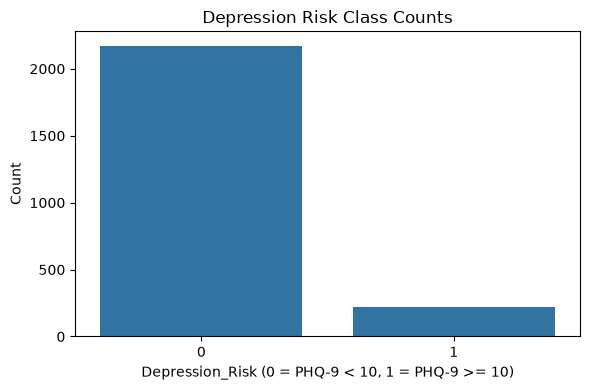

In [45]:
# Compare the counts of participants below and above the project cutoff.
plt.figure(figsize=(6, 4))
sns.countplot(x="Depression_Risk", data=df_NHANES_60plus)
plt.title("Depression Risk Class Counts")
plt.xlabel("Depression_Risk (0 = PHQ-9 < 10, 1 = PHQ-9 >= 10)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

#### BMI and PHQ9_Total Scatter Plot

Use the Tutorial 4 scatter-plot format to explore how BMI relates to the continuous PHQ-9 score among adults aged 60+. This is for data exploration only; `PHQ9_Total` is not included in `X`.

In [ ]:
# Explore BMI values against PHQ-9 total scores.
plt.scatter(df_NHANES_60plus["BMXBMI"], df_NHANES_60plus["PHQ9_Total"], s=1)
plt.title("BMI vs PHQ-9 Total for Adults Aged 60+")
plt.xlabel("BMI (kg/m^2)")
plt.ylabel("PHQ9_Total (0-27)")
plt.show()

## Step 4: Data Quality Checks

### 4.1 Check SEQN in Each Source Dataset

Check for missing and duplicate participant IDs in separate cells.

#### Missing SEQN


In [46]:
# Check missing participant IDs in each source file.
print("DEMO missing SEQN:", df_DEMO["SEQN"].isnull().sum())
print("DPQ missing SEQN:", df_DPQ["SEQN"].isnull().sum())
print("MCQ missing SEQN:", df_MCQ["SEQN"].isnull().sum())
print("INQ missing SEQN:", df_INQ["SEQN"].isnull().sum())
print("PAQ missing SEQN:", df_PAQ["SEQN"].isnull().sum())
print("SLQ missing SEQN:", df_SLQ["SEQN"].isnull().sum())
print("ALQ missing SEQN:", df_ALQ["SEQN"].isnull().sum())
print("BMX missing SEQN:", df_BMX["SEQN"].isnull().sum())

DEMO missing SEQN: 0
DPQ missing SEQN: 0
MCQ missing SEQN: 0
INQ missing SEQN: 0
PAQ missing SEQN: 0
SLQ missing SEQN: 0
ALQ missing SEQN: 0
BMX missing SEQN: 0


#### Duplicate SEQN


In [47]:
# Check duplicate participant IDs in each source file.
print("DEMO duplicate SEQN:", df_DEMO["SEQN"].duplicated().sum())
print("DPQ duplicate SEQN:", df_DPQ["SEQN"].duplicated().sum())
print("MCQ duplicate SEQN:", df_MCQ["SEQN"].duplicated().sum())
print("INQ duplicate SEQN:", df_INQ["SEQN"].duplicated().sum())
print("PAQ duplicate SEQN:", df_PAQ["SEQN"].duplicated().sum())
print("SLQ duplicate SEQN:", df_SLQ["SEQN"].duplicated().sum())
print("ALQ duplicate SEQN:", df_ALQ["SEQN"].duplicated().sum())
print("BMX duplicate SEQN:", df_BMX["SEQN"].duplicated().sum())

DEMO duplicate SEQN: 0
DPQ duplicate SEQN: 0
MCQ duplicate SEQN: 0
INQ duplicate SEQN: 0
PAQ duplicate SEQN: 0
SLQ duplicate SEQN: 0
ALQ duplicate SEQN: 0
BMX duplicate SEQN: 0


### 4.2 Check the Merged Dataset and PHQ-9 Values

In [48]:
# Check merge counts, PHQ-9 validity, score range, and remaining missing values.
print("Age-eligible DEMO rows before merging:", df_older_adults.shape[0])
print("Rows after merging:", df_NHANES_merged.shape[0])
print("Complete PHQ-9 records after cleaning:", df_NHANES_60plus.shape[0])
print("Missing SEQN after merging:", df_NHANES_merged["SEQN"].isnull().sum())
print("Duplicate SEQN after merging:", df_NHANES_merged["SEQN"].duplicated().sum())

print("Invalid PHQ-9 responses after cleaning:", int((~df_NHANES_60plus[dpq_items].isin([0, 1, 2, 3])).sum().sum()))
print("Incomplete PHQ-9 records remaining:", int(df_NHANES_60plus[dpq_items].isnull().any(axis=1).sum()))
print("PHQ9_Total within 0-27:", df_NHANES_60plus["PHQ9_Total"].between(0, 27).all())
print("Missing Depression_Risk values:", df_NHANES_60plus["Depression_Risk"].isnull().sum())

print("Missing values in the merged dataset:")
missing_values = df_NHANES_60plus.isnull().sum()
print(missing_values[missing_values > 0].sort_values(ascending=False))

Age-eligible DEMO rows before merging: 3504
Rows after merging: 3504
Complete PHQ-9 records after cleaning: 2394
Missing SEQN after merging: 0
Duplicate SEQN after merging: 0
Invalid PHQ-9 responses after cleaning: 0
Incomplete PHQ-9 records remaining: 0
PHQ9_Total within 0-27: True
Missing Depression_Risk values: 0
Missing values in the merged dataset:


RIDAGEMN    2394
BMDBMIC     2394
MCQ500      2394
BMXRECUM    2394
BMIRECUM    2394
            ... 
PAD680        16
BMXHT         14
ALQ111        12
PAD810Q        1
PAD790Q        1
Length: 68, dtype: int64


## Step 5: Define X and y

Use continuous numeric variables as features: age, income-to-poverty ratio, BMI, weekday and weekend sleep duration, and sedentary activity time. Exclude `SEQN`, PHQ-9 items, `PHQ9_Total`, and helper columns from `X`.

The Lab 4 tutorial demonstrates filling missing values with a column mean. Apply this to the selected numeric features after each train-test split: calculate means from `X_train`, fill missing training values with those means, and use the same means for the corresponding test set. This keeps the same simple `fillna()` method while avoiding mean values calculated from the test data. The target has no missing PHQ-9 values because only complete nine-item records are retained.

In [49]:
# Select candidate features and keep PHQ-9 items and derived values out of X.
feature_columns = ["RIDAGEYR", "INDFMPIR", "BMXBMI","SLD012", "SLD013", "PAD680"]

X = df_NHANES_60plus[feature_columns]
y = df_NHANES_60plus["Depression_Risk"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:")
print(X.columns.tolist())
print("PHQ-9 items included in X:", [col for col in dpq_items if col in X.columns])
print("Target distribution:")
print(y.value_counts())
print("Missing values in selected features:")
missing_feature_values = X.isnull().sum()
print(missing_feature_values[missing_feature_values > 0].sort_values(ascending=False))

X shape: (2394, 6)
y shape: (2394,)
Features:
['RIDAGEYR', 'INDFMPIR', 'BMXBMI', 'SLD012', 'SLD013', 'PAD680']
PHQ-9 items included in X: []
Target distribution:
Depression_Risk
0    2171
1     223
Name: count, dtype: int64
Missing values in selected features:
INDFMPIR    288
SLD012       35
SLD013       31
BMXBMI       23
PAD680       16
dtype: int64


## Step 6: Train-Test Split

Create separate 5%, 15%, and 25% test splits using the `train_test_split` method shown in Tutorial 3. For each split, calculate feature means from its training data and use those same means to fill missing values in the training and test sets.

In [50]:
# Create each requested split and fill feature missing values from its training mean.
# 5% test set
X_train_05, X_test_05, y_train_05, y_test_05 = train_test_split(
    X, y, test_size=0.05, random_state=1)
X_train_mean_05 = X_train_05.mean()
X_train_05 = X_train_05.fillna(X_train_mean_05)
X_test_05 = X_test_05.fillna(X_train_mean_05)

print("5% split:", X_train_05.shape, X_test_05.shape)
print("Remaining missing values in 5% training set:", X_train_05.isnull().sum().sum())
print("Remaining missing values in 5% test set:", X_test_05.isnull().sum().sum())

5% split: (2274, 6) (120, 6)
Remaining missing values in 5% training set: 0
Remaining missing values in 5% test set: 0


In [51]:
# 15% test set
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(
    X, y, test_size=0.15, random_state=1)
X_train_mean_15 = X_train_15.mean()
X_train_15 = X_train_15.fillna(X_train_mean_15)
X_test_15 = X_test_15.fillna(X_train_mean_15)

print("15% split:", X_train_15.shape, X_test_15.shape)
print("Remaining missing values in 15% training set:", X_train_15.isnull().sum().sum())
print("Remaining missing values in 15% test set:", X_test_15.isnull().sum().sum())

15% split: (2034, 6) (360, 6)
Remaining missing values in 15% training set: 0
Remaining missing values in 15% test set: 0


In [52]:
# 25% test set
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X, y, test_size=0.25, random_state=1)
X_train_mean_25 = X_train_25.mean()
X_train_25 = X_train_25.fillna(X_train_mean_25)
X_test_25 = X_test_25.fillna(X_train_mean_25)

print("25% split:", X_train_25.shape, X_test_25.shape)
print("Remaining missing values in 25% training set:", X_train_25.isnull().sum().sum())
print("Remaining missing values in 25% test set:", X_test_25.isnull().sum().sum())

25% split: (1795, 6) (599, 6)
Remaining missing values in 25% training set: 0
Remaining missing values in 25% test set: 0


## Step 7: Build ML Models

Fit Logistic Regression and Random Forest on each training split. Scale features for Logistic Regression as shown in Tutorial 5; fit Random Forest on the original split features. Generate test-set predictions for both models.

### 7.1 Logistic Regression and Random Forest with 5% Test Set


In [53]:
# Fit Logistic Regression for the 5% test split.
# Scale the split features for Logistic Regression, following Tutorial 5.
sc_05 = StandardScaler()
X_train_scaled_05 = sc_05.fit_transform(X_train_05)
X_test_scaled_05 = sc_05.transform(X_test_05)

log_model_05 = LogisticRegression()
log_model_05.fit(X_train_scaled_05, y_train_05)
log_pred_05 = log_model_05.predict(X_test_scaled_05)

# Fit Random Forest for the same split.
rf_model_05 = RandomForestClassifier(n_estimators=1000)
rf_model_05.fit(X_train_05, y_train_05)
rf_pred_05 = rf_model_05.predict(X_test_05)

print("Both models fitted for the 5% test split.")

Both models fitted for the 5% test split.


### 7.2 Logistic Regression and Random Forest with 15% Test Set


In [54]:
# Fit Logistic Regression for the 15% test split.
# Scale the split features for Logistic Regression, following Tutorial 5.
sc_15 = StandardScaler()
X_train_scaled_15 = sc_15.fit_transform(X_train_15)
X_test_scaled_15 = sc_15.transform(X_test_15)

log_model_15 = LogisticRegression()
log_model_15.fit(X_train_scaled_15, y_train_15)
log_pred_15 = log_model_15.predict(X_test_scaled_15)

# Fit Random Forest for the same split.
rf_model_15 = RandomForestClassifier(n_estimators=1000)
rf_model_15.fit(X_train_15, y_train_15)
rf_pred_15 = rf_model_15.predict(X_test_15)

print("Both models fitted for the 15% test split.")

Both models fitted for the 15% test split.


### 7.3 Logistic Regression and Random Forest with 25% Test Set


In [55]:
# Fit Logistic Regression for the 25% test split.
# Scale the split features for Logistic Regression, following Tutorial 5.
sc_25 = StandardScaler()
X_train_scaled_25 = sc_25.fit_transform(X_train_25)
X_test_scaled_25 = sc_25.transform(X_test_25)

log_model_25 = LogisticRegression()
log_model_25.fit(X_train_scaled_25, y_train_25)
log_pred_25 = log_model_25.predict(X_test_scaled_25)

# Fit Random Forest for the same split.
rf_model_25 = RandomForestClassifier(n_estimators=1000)
rf_model_25.fit(X_train_25, y_train_25)
rf_pred_25 = rf_model_25.predict(X_test_25)

print("Both models fitted for the 25% test split.")

Both models fitted for the 25% test split.


## Step 8: Cross-validation

Use five-fold cross-validation on each training split to compare model accuracy. With `cv=5`, scikit-learn uses stratified folds for binary classifiers by default ([official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)). Logistic Regression uses the scaled training features; Random Forest uses the unscaled features.

### 8.1 Five-fold CV on 5% Test Split

In [56]:
# Calculate five-fold cross-validation accuracy for both models.
cv_lr_05 = cross_val_score(estimator=log_model_05, X=X_train_scaled_05, y=y_train_05, scoring="accuracy", cv=5)
cv_rf_05 = cross_val_score(estimator=rf_model_05, X=X_train_05, y=y_train_05, scoring="accuracy", cv=5)

print("5% split - Logistic Regression CV scores:", cv_lr_05)
print("5% split - Logistic Regression mean accuracy:", cv_lr_05.mean())
print("5% split - Random Forest CV scores:", cv_rf_05)
print("5% split - Random Forest mean accuracy:", cv_rf_05.mean())

5% split - Logistic Regression CV scores: [0.90549451 0.9032967  0.9032967  0.9032967  0.90528634]
5% split - Logistic Regression mean accuracy: 0.90413419179939
5% split - Random Forest CV scores: [0.8967033  0.89450549 0.9032967  0.9032967  0.90748899]
5% split - Random Forest mean accuracy: 0.9010582369172677


### 8.3 Five-fold CV on 15% Test Split

In [57]:
# Calculate five-fold cross-validation accuracy for both models.
cv_lr_15 = cross_val_score(estimator=log_model_15, X=X_train_scaled_15, y=y_train_15, scoring="accuracy", cv=5)
cv_rf_15 = cross_val_score(estimator=rf_model_15, X=X_train_15, y=y_train_15, scoring="accuracy", cv=5)

print("15% split - Logistic Regression CV scores:", cv_lr_15)
print("15% split - Logistic Regression mean accuracy:", cv_lr_15.mean())
print("15% split - Random Forest CV scores:", cv_rf_15)
print("15% split - Random Forest mean accuracy:", cv_rf_15.mean())

15% split - Logistic Regression CV scores: [0.90663391 0.90663391 0.9017199  0.90663391 0.908867  ]
15% split - Logistic Regression mean accuracy: 0.9060977233391027
15% split - Random Forest CV scores: [0.9017199  0.8992629  0.90663391 0.90909091 0.91133005]
15% split - Random Forest mean accuracy: 0.90560753319374


### 8.5 Five-fold CV on 25% Test Split

In [58]:
# Calculate five-fold cross-validation accuracy for both models.
cv_lr_25 = cross_val_score(estimator=log_model_25, X=X_train_scaled_25, y=y_train_25, scoring="accuracy", cv=5)
cv_rf_25 = cross_val_score(estimator=rf_model_25, X=X_train_25, y=y_train_25, scoring="accuracy", cv=5)

print("25% split - Logistic Regression CV scores:", cv_lr_25)
print("25% split - Logistic Regression mean accuracy:", cv_lr_25.mean())
print("25% split - Random Forest CV scores:", cv_rf_25)
print("25% split - Random Forest mean accuracy:", cv_rf_25.mean())

25% split - Logistic Regression CV scores: [0.90807799 0.90807799 0.90807799 0.90529248 0.90529248]
25% split - Logistic Regression mean accuracy: 0.9069637883008357
25% split - Random Forest CV scores: [0.90250696 0.89972145 0.90529248 0.90529248 0.90529248]
25% split - Random Forest mean accuracy: 0.9036211699164346


## Step 9: Model Evaluation

Evaluate each model on its held-out test set using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix. The classification report shows Precision, Recall, and F1-score for each class.

### 9.1 Evaluation on 5% Test Set

Logistic Regression accuracy: 0.9583333333333334
Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       115
           1       0.00      0.00      0.00         5

    accuracy                           0.96       120
   macro avg       0.48      0.50      0.49       120
weighted avg       0.92      0.96      0.94       120

Logistic Regression confusion matrix:
[[115   0]
 [  5   0]]
Random Forest accuracy: 0.9416666666666667
Random Forest classification report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       115
           1       0.00      0.00      0.00         5

    accuracy                           0.94       120
   macro avg       0.48      0.49      0.48       120
weighted avg       0.92      0.94      0.93       120

Random Forest confusion matrix:
[[113   2]
 [  5   0]]


/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

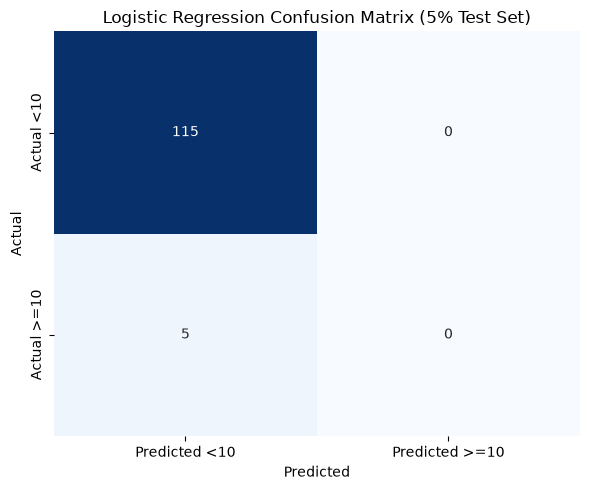

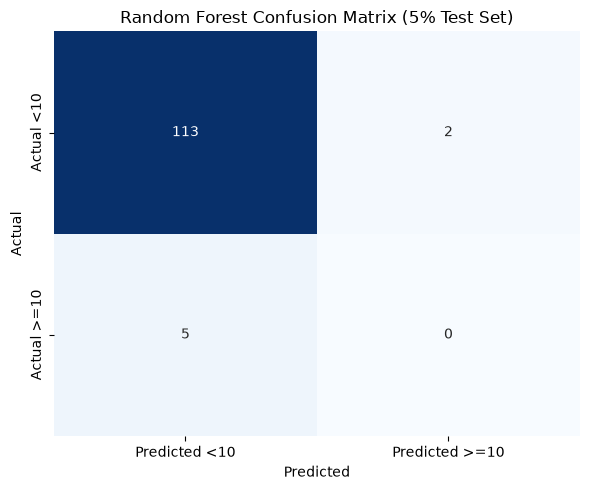

In [59]:
# Evaluate Logistic Regression on the 5% test set.
print("Logistic Regression accuracy:", metrics.accuracy_score(y_test_05, log_pred_05))
print("Logistic Regression classification report:")
print(classification_report(y_test_05, log_pred_05))
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test_05, log_pred_05))

# Evaluate Random Forest on the same test set.
print("Random Forest accuracy:", metrics.accuracy_score(y_test_05, rf_pred_05))
print("Random Forest classification report:")
print(classification_report(y_test_05, rf_pred_05))
print("Random Forest confusion matrix:")
print(confusion_matrix(y_test_05, rf_pred_05))

# Plot Logistic Regression confusion matrix for the 5% test set.
cm_lr_05 = confusion_matrix(y_test_05, log_pred_05, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_05, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Logistic Regression Confusion Matrix (5% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Plot Random Forest confusion matrix for the same test set.
cm_rf_05 = confusion_matrix(y_test_05, rf_pred_05, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_05, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Random Forest Confusion Matrix (5% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

### 9.3 Evaluation on 15% Test Set

Logistic Regression accuracy: 0.9055555555555556
Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       326
           1       0.00      0.00      0.00        34

    accuracy                           0.91       360
   macro avg       0.45      0.50      0.48       360
weighted avg       0.82      0.91      0.86       360

Logistic Regression confusion matrix:
[[326   0]
 [ 34   0]]
Random Forest accuracy: 0.9027777777777778
Random Forest classification report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       326
           1       0.43      0.09      0.15        34

    accuracy                           0.90       360
   macro avg       0.67      0.54      0.55       360
weighted avg       0.87      0.90      0.87       360

Random Forest confusion matrix:
[[322   4]
 [ 31   3]]


/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

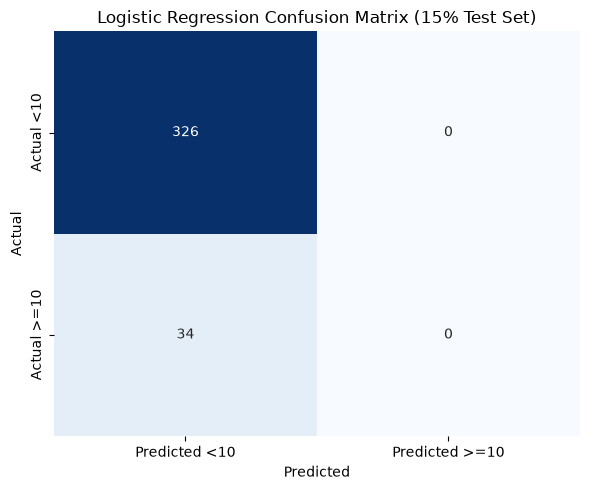

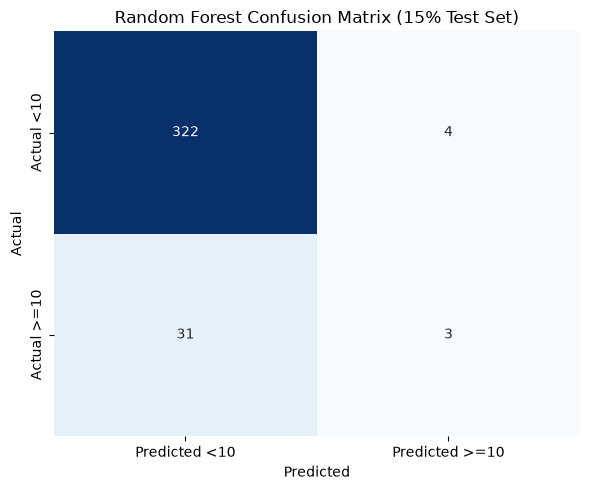

In [60]:
# Evaluate Logistic Regression on the 15% test set.
print("Logistic Regression accuracy:", metrics.accuracy_score(y_test_15, log_pred_15))
print("Logistic Regression classification report:")
print(classification_report(y_test_15, log_pred_15))
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test_15, log_pred_15))

# Evaluate Random Forest on the same test set.
print("Random Forest accuracy:", metrics.accuracy_score(y_test_15, rf_pred_15))
print("Random Forest classification report:")
print(classification_report(y_test_15, rf_pred_15))
print("Random Forest confusion matrix:")
print(confusion_matrix(y_test_15, rf_pred_15))

# Plot Logistic Regression confusion matrix for the 15% test set.
cm_lr_15 = confusion_matrix(y_test_15, log_pred_15, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_15, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Logistic Regression Confusion Matrix (15% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Plot Random Forest confusion matrix for the same test set.
cm_rf_15 = confusion_matrix(y_test_15, rf_pred_15, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_15, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Random Forest Confusion Matrix (15% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

### 9.5 Evaluation on 25% Test Set

Logistic Regression accuracy: 0.9065108514190318
Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       543
           1       0.00      0.00      0.00        56

    accuracy                           0.91       599
   macro avg       0.45      0.50      0.48       599
weighted avg       0.82      0.91      0.86       599

Logistic Regression confusion matrix:
[[543   0]
 [ 56   0]]
Random Forest accuracy: 0.9048414023372288
Random Forest classification report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       543
           1       0.44      0.07      0.12        56

    accuracy                           0.90       599
   macro avg       0.68      0.53      0.54       599
weighted avg       0.87      0.90      0.87       599

Random Forest confusion matrix:
[[538   5]
 [ 52   4]]


/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/paki/Documents/CCT/cct/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

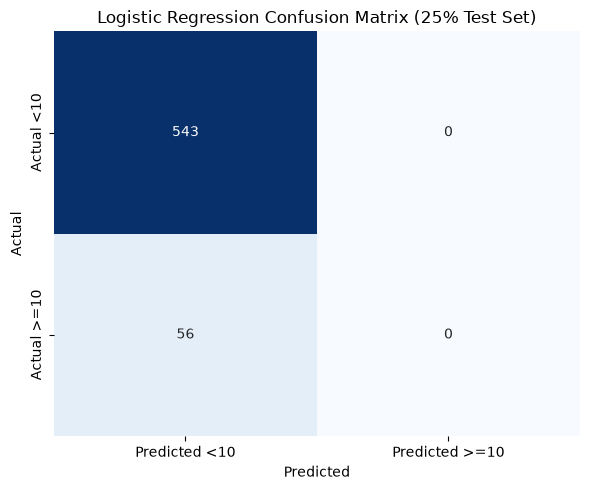

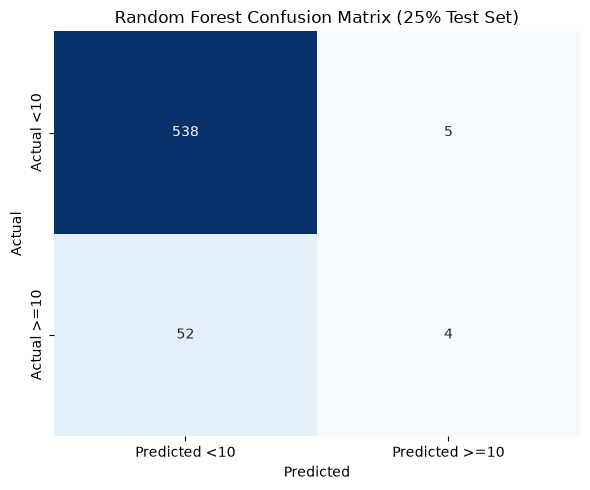

In [61]:
# Evaluate Logistic Regression on the 25% test set.
print("Logistic Regression accuracy:", metrics.accuracy_score(y_test_25, log_pred_25))
print("Logistic Regression classification report:")
print(classification_report(y_test_25, log_pred_25))
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test_25, log_pred_25))

# Evaluate Random Forest on the same test set.
print("Random Forest accuracy:", metrics.accuracy_score(y_test_25, rf_pred_25))
print("Random Forest classification report:")
print(classification_report(y_test_25, rf_pred_25))
print("Random Forest confusion matrix:")
print(confusion_matrix(y_test_25, rf_pred_25))

# Plot Logistic Regression confusion matrix for the 25% test set.
cm_lr_25 = confusion_matrix(y_test_25, log_pred_25, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_25, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Logistic Regression Confusion Matrix (25% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Plot Random Forest confusion matrix for the same test set.
cm_rf_25 = confusion_matrix(y_test_25, rf_pred_25, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_25, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Random Forest Confusion Matrix (25% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()